In [37]:
# Importing libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

In [49]:
from pathlib import Path

DATA_DIR = Path("/home/bwong/M3/M3-Stock-Price-Models/notebooks/data/005380.KS.csv")

if not DATA_DIR.is_file():
    raise FileNotFoundError(f"CSV not found: {DATA_DIR}")

df = pd.read_csv(DATA_DIR)
df.head(10)

,Date,open,high,low,close,adjclose,volume,ingested_at_utc
0,2016-01-04,147500.0,148000.0,143500.0,144000.0,100985.703125,445332,2026-09-25 05:54:15.067145+00:00
1,2016-01-05,143000.0,145000.0,142000.0,143500.0,100635.078125,530496,2026-09-25 05:54:15.067145+00:00
2,2016-01-06,144000.0,145000.0,139000.0,140000.0,98180.546875,769406,2026-09-25 05:54:15.067145+00:00
3,2016-01-07,138500.0,140000.0,137500.0,137500.0,96427.320312,586187,2026-09-25 05:54:15.067145+00:00
4,2016-01-08,134500.0,138000.0,133500.0,136500.0,95726.054688,888701,2026-09-25 05:54:15.067145+00:00
5,2016-01-11,134500.0,140500.0,134000.0,140000.0,98180.546875,542749,2026-09-25 05:54:15.067145+00:00
6,2016-01-12,140500.0,141500.0,139000.0,139500.0,97829.898438,386506,2026-09-25 05:54:15.067145+00:00
7,2016-01-13,140500.0,141500.0,139500.0,140500.0,98531.179688,338336,2026-09-25 05:54:15.067145+00:00
8,2016-01-14,138500.0,143500.0,136500.0,141000.0,98881.835938,664829,2026-09-25 05:54:15.067145+00:00
9,2016-01-15,141000.0,142000.0,136500.0,138500.0,97128.625000,568653,2026-09-25 05:54:15.067145+00:00


## Plot the graph of the share based on closing price

<Axes: xlabel='Date'>

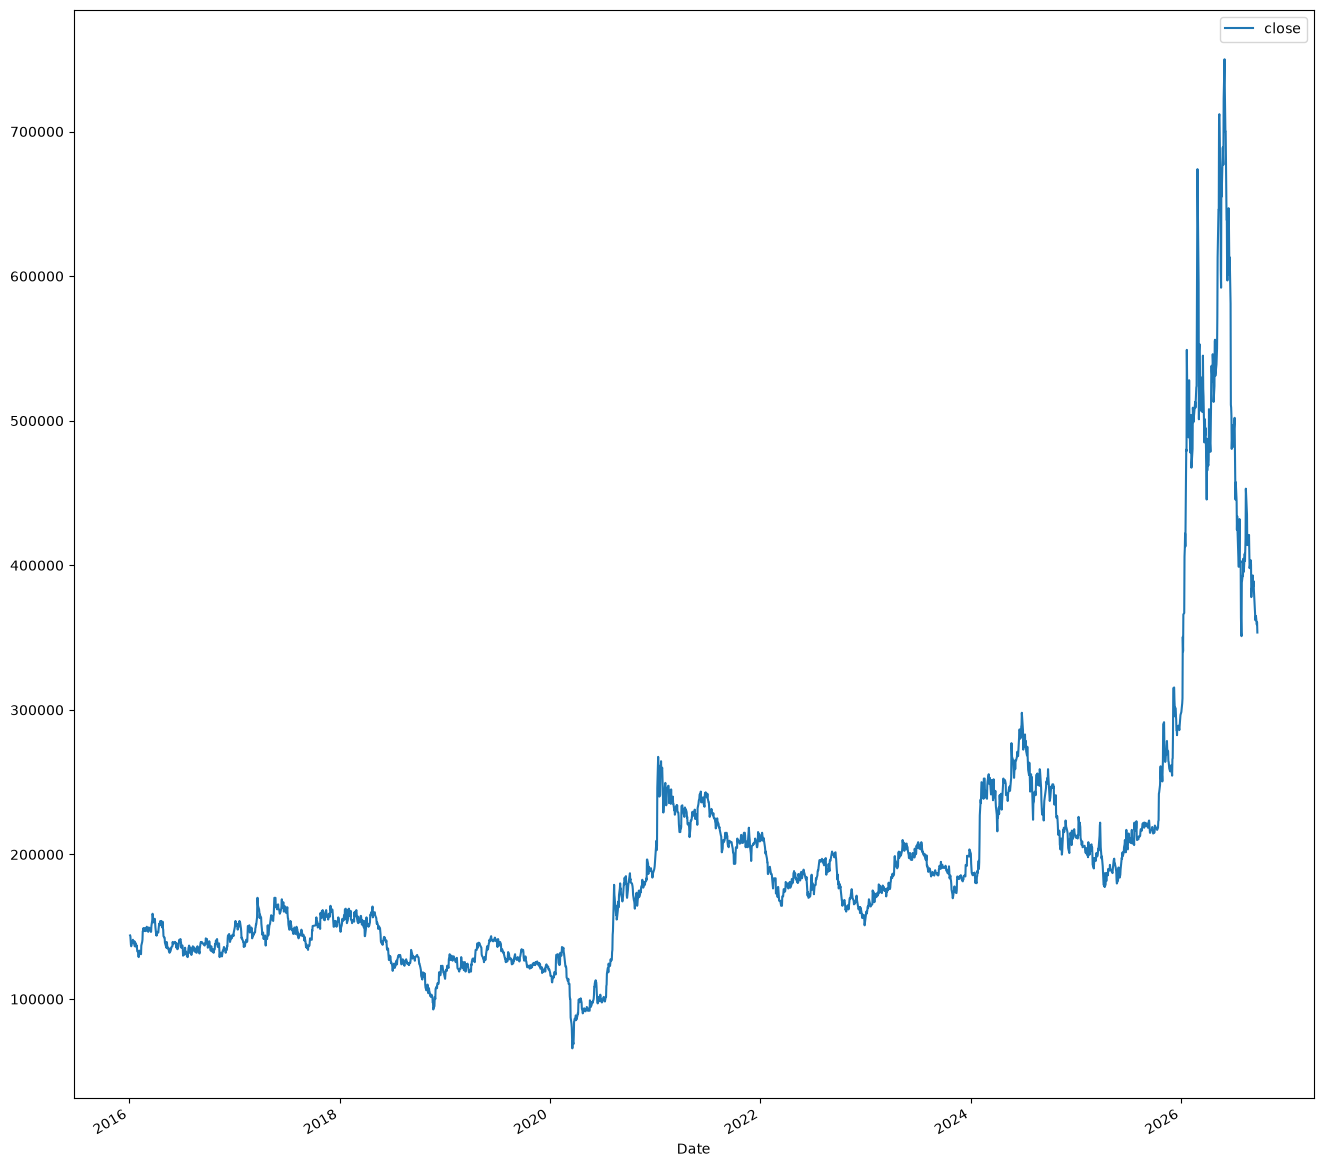

In [50]:
df.index = pd.to_datetime(df['Date'], format='%Y-%m-%d')
df.head(10)
df = df.drop(columns=['open', 'high', 'low', 'adjclose', 'volume', 'ingested_at_utc'])

df.plot(y ='close', figsize=(16, 16))

## Look at the lag features

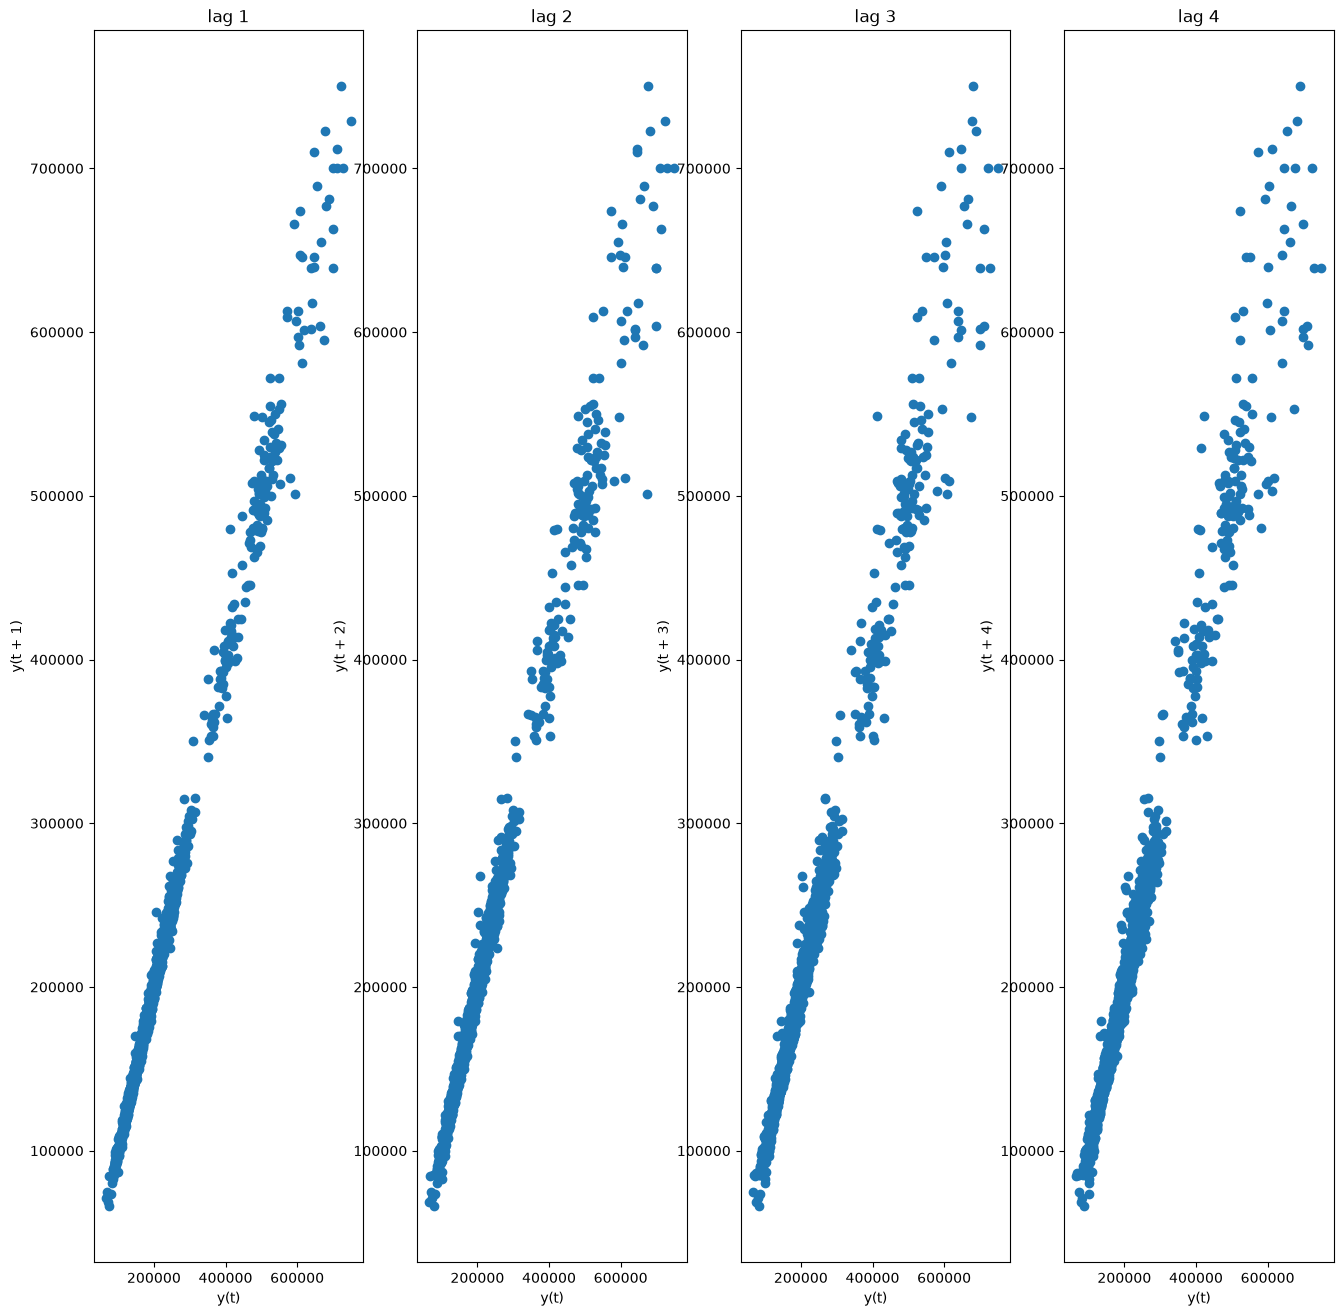

In [51]:
fig, axs = plt.subplots(ncols=4, figsize=(16,16))
for ax, i in zip(axs.flat, range(1,10)):
    pd.plotting.lag_plot(df['close'], lag=i, ax=ax)
    ax.set_title('lag '+ str(i) )

plt.show()

## There is a linear relationship between current stock values and past stock values

Text(0.5, 0, 'lags')

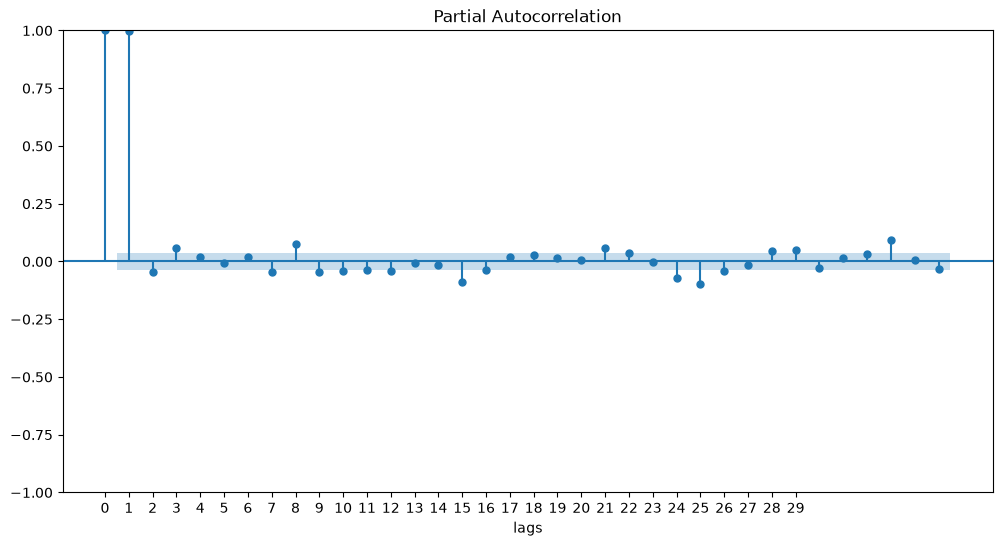

In [52]:
from statsmodels.graphics.tsaplots import plot_pacf
_, ax = plt.subplots(figsize=(12, 6))
plot_pacf(df['close'].dropna(), ax=ax, method='ywm')
ind = [i for i in range(30)]
ax.set_xticks(ind)
ax.set_xlabel('lags')

## The partial autocorrection shows that we can capture the dependence with lags 1,2,21 and 24. We will create these features. 

In [53]:
X = df.drop(columns=['Date']).copy()

X['lag1'] = X['close'].shift(1)
X['lag2'] = X['close'].shift(2)
X['lag21'] = X['close'].shift(21)
X['lag24'] = X['close'].shift(24)


In [54]:
X = X.fillna(X['close'].mean())
X = X.drop(['close'], axis=1)


## Create the Model using linear regression

In [55]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

y = df['close'].copy()
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=100, shuffle=False)
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = pd.Series(model.predict(X_train), index=y_train.index)
pred = pd.Series(model.predict(X_test), index=y_test.index)
y_fore = pd.Series(model.predict(X_test), index=y_test.index)

Text(0.5, 1.0, 'ground truth and prediction plot')

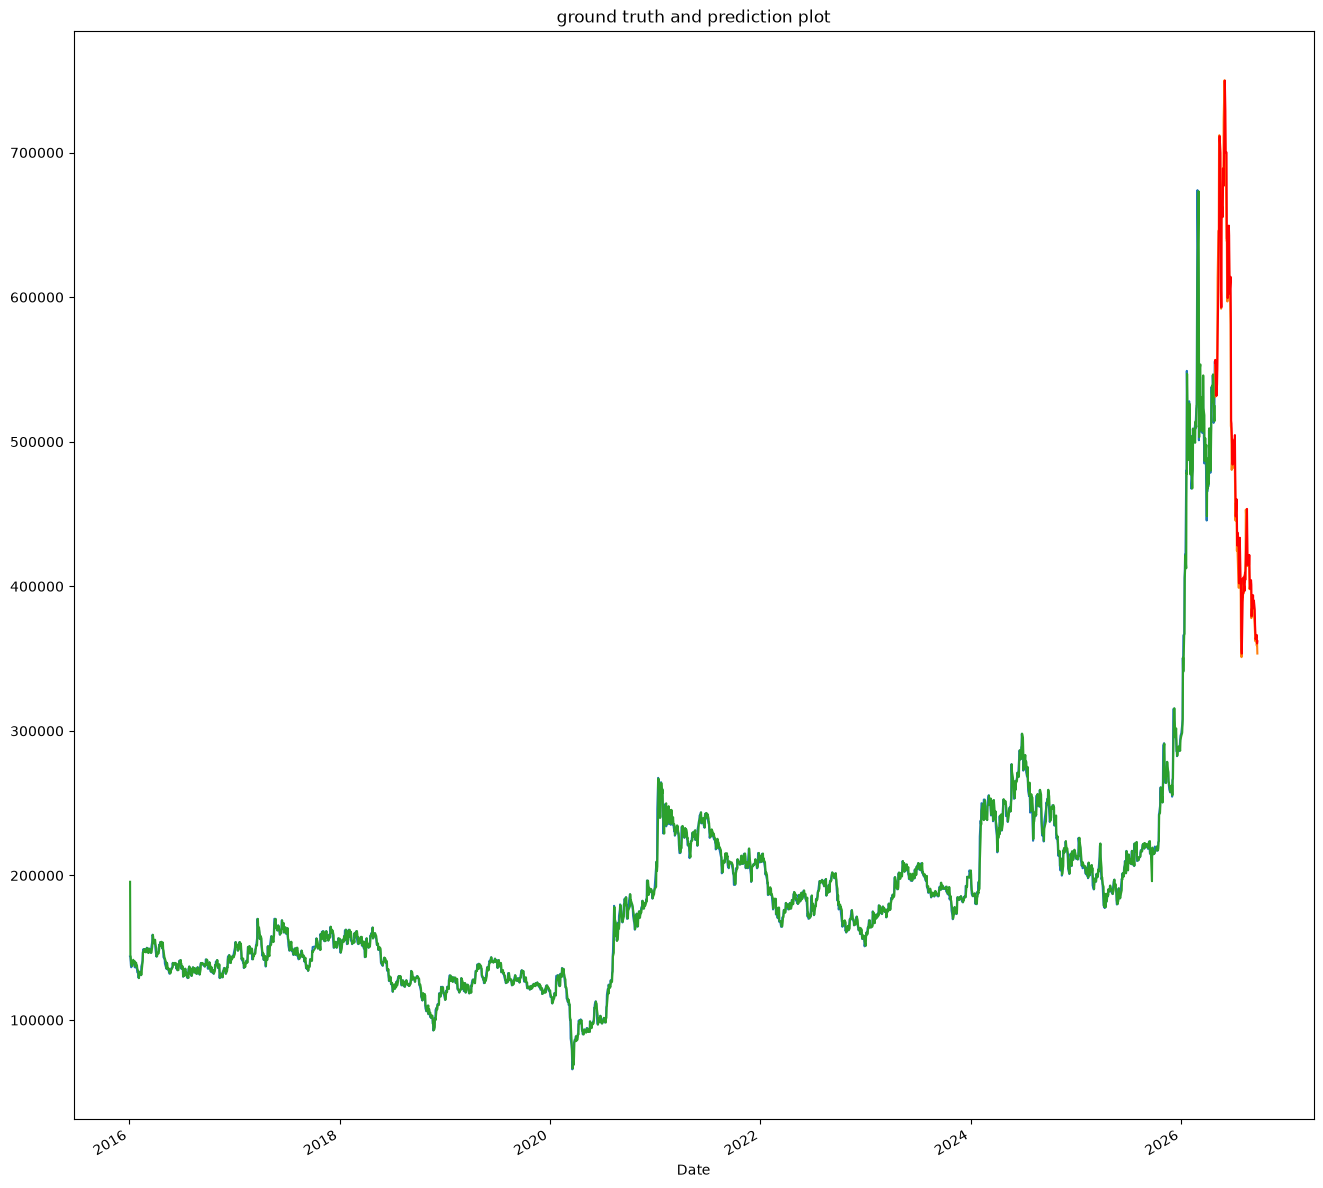

In [56]:
ax = y_train.plot()
ax = y_test.plot()
ax = y_pred.plot(ax=ax) #prediction for the training set
_ = y_fore.plot(ax=ax, color='red', figsize=(16,16)) #prediciton for the set 
ax.set_title('ground truth and prediction plot')

## Zoom in on the accuracy

Text(0.5, 1.0, 'Train/prediction comparison')

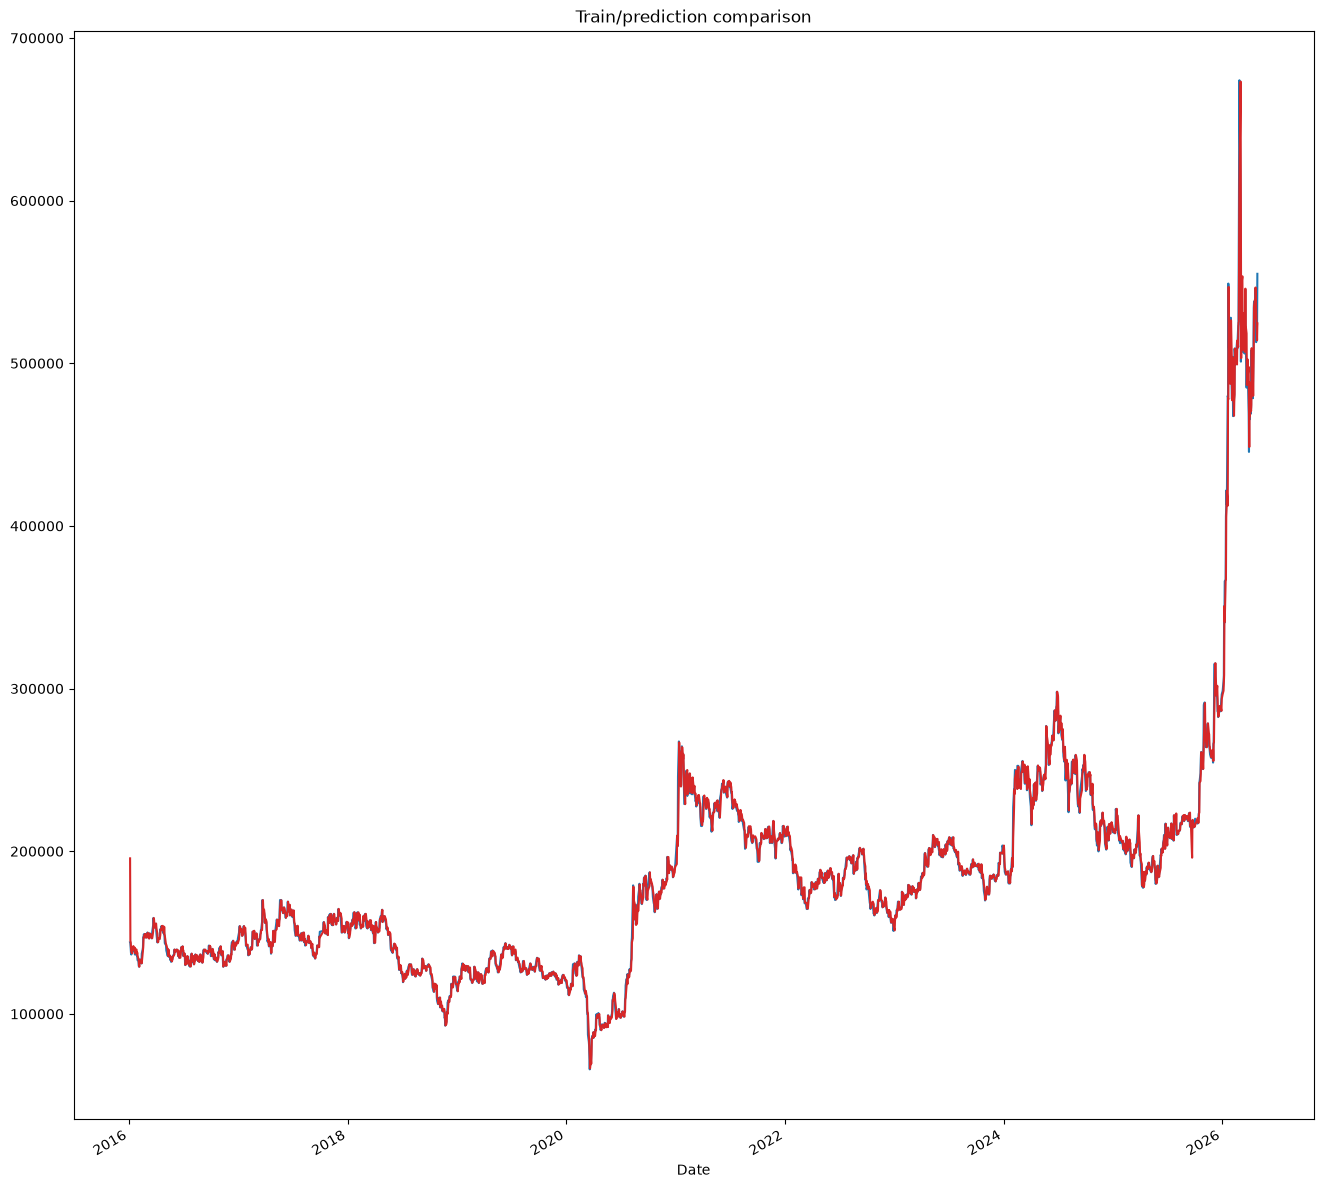

In [57]:
ax = y_train.plot()
_ = y_pred.plot(ax=ax, color='C3', figsize=(16, 16) )
ax.set_title('Train/prediction comparison')

Text(0.5, 1.0, 'Test/prediction comparison')

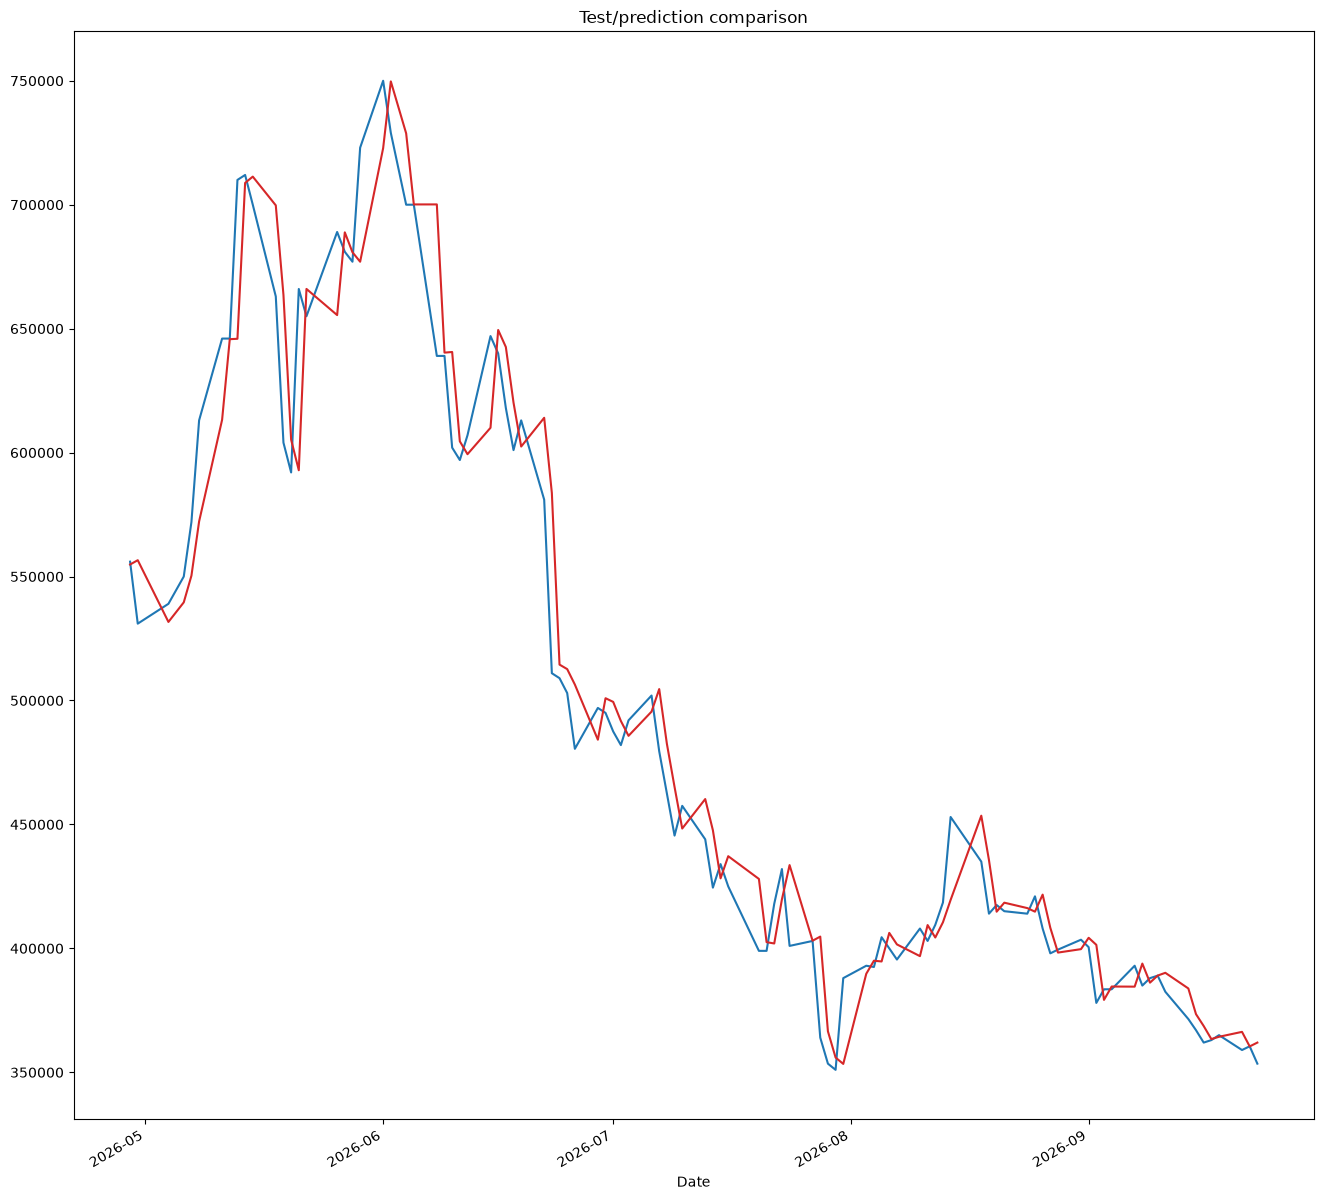

In [58]:
ax = y_test.plot()
_ = y_fore.plot(ax=ax, color='C3', figsize=(16, 16) )
ax.set_title('Test/prediction comparison')

## EVALUATION using RMSE

In [59]:
train_rmse = root_mean_squared_error(y_train, y_pred)
test_rmse = root_mean_squared_error(y_test, y_fore)  # y_fore is same as pred
print(f"Train RMSE: {train_rmse:.2f}\nTest RMSE: {test_rmse:.2f}")

test_r2 = r2_score(y_test, pred)
print(f"Test R2: R² ={test_r2:.3f}")

Train RMSE: 6164.58
Test RMSE: 22685.25
Test R2: R² =0.963
